# 🧹 Tiền xử lý Dữ liệu TFT

Notebook này thực hiện:
1. Nạp và kiểm tra dữ liệu thô
2. Làm sạch: missing values, outliers, duplicates
3. Gán nhãn Win/Lose (Top 4)
4. Tạo transaction format cho Association Rule Mining
5. Tạo co-occurrence matrix cho Graph Mining


In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
import warnings
warnings.filterwarnings('ignore')

from src.preprocessor import TFTPreprocessor

pp = TFTPreprocessor()
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

## 1. Nạp dữ liệu thô

In [2]:
df = pp.load_data('../data/raw/tft_matches.csv')
print(f'Shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
df.head(3)

✅ Loaded 399,998 records from ../data/raw/tft_matches.csv
Shape: (399998, 14)
Columns: ['match_id', 'player_id', 'placement', 'tier', 'level', 'rounds_survived', 'game_duration_s', 'champions', 'champion_stars', 'items', 'active_traits', 'num_champions', 'num_items', 'num_active_traits']


,match_id,player_id,placement,tier,level,rounds_survived,game_duration_s,champions,champion_stars,items,active_traits,num_champions,num_items,num_active_traits
0,KR_4247538593,KR_4247538593_1,1,Challenger,8,35,2142.470703,"[""JarvanIV"", ""Sona"", ""Rakan"", ""XinZhao"", ""Neek...","{""JarvanIV"": 3, ""Sona"": 3, ""Rakan"": 3, ""XinZha...","{""JarvanIV"": [27], ""Sona"": [46], ""Rakan"": [37,...","{""DarkStar"": 2, ""Protector"": 4, ""Rebel"": 1, ""S...",8,8,7
1,KR_4247538593,KR_4247538593_2,2,Challenger,9,35,2142.470703,"[""Malphite"", ""Yasuo"", ""Sona"", ""MasterYi"", ""Jin...","{""Malphite"": 2, ""Yasuo"": 2, ""Sona"": 2, ""Master...","{""Malphite"": [7], ""Yasuo"": [99, 22, 23], ""Kayl...","{""Blaster"": 2, ""Mercenary"": 1, ""Rebel"": 6, ""Se...",9,12,9
2,KR_4247538593,KR_4247538593_3,3,Challenger,8,34,2142.470703,"[""KaiSa"", ""Annie"", ""Shaco"", ""Rumble"", ""Karma"",...","{""KaiSa"": 2, ""Annie"": 2, ""Shaco"": 2, ""Rumble"":...","{""KaiSa"": [99, 2, 23], ""Annie"": [37], ""Shaco"":...","{""Cybernetic"": 1, ""DarkStar"": 3, ""Demolitionis...",8,10,8


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 399998 entries, 0 to 399997
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   match_id           399998 non-null  object 
 1   player_id          399998 non-null  object 
 2   placement          399998 non-null  int64  
 3   tier               399998 non-null  object 
 4   level              399998 non-null  int64  
 5   rounds_survived    399998 non-null  int64  
 6   game_duration_s    399998 non-null  float64
 7   champions          399998 non-null  object 
 8   champion_stars     399998 non-null  object 
 9   items              399998 non-null  object 
 10  active_traits      399998 non-null  object 
 11  num_champions      399998 non-null  int64  
 12  num_items          399998 non-null  int64  
 13  num_active_traits  399998 non-null  int64  
dtypes: float64(1), int64(6), object(7)
memory usage: 42.7+ MB


In [4]:
df.describe()

,placement,level,rounds_survived,game_duration_s,num_champions,num_items,num_active_traits
count,399998.000000,399998.000000,399998.000000,399998.000000,399998.000000,399998.000000,399998.000000
mean,4.499067,7.854157,33.526310,2158.849411,7.892077,8.740541,8.641571
std,2.292066,0.783634,4.806737,143.213755,0.947996,2.359321,1.481610
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,7.000000,30.000000,2066.230042,7.000000,7.000000,8.000000
50%,4.000000,8.000000,34.000000,2153.773193,8.000000,9.000000,9.000000
75%,6.000000,8.000000,37.000000,2247.653870,8.000000,10.000000,10.000000
max,8.000000,9.000000,51.000000,2775.935547,12.000000,27.000000,18.000000


## 2. Kiểm tra Missing Values

Không có missing values! ✅


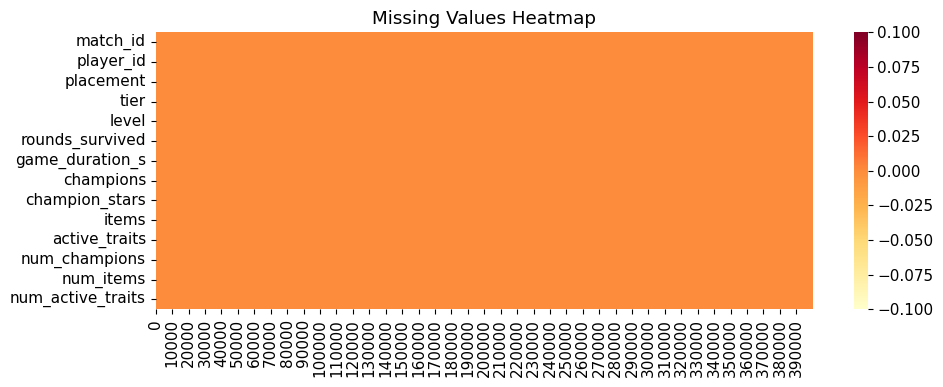

In [5]:
# Đếm missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Count': missing, 'Percent': missing_pct})
print(missing_df[missing_df['Count'] > 0] if missing.sum() > 0 else 'Không có missing values! ✅')

# Visualize missing
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(df.isnull().T, cbar=True, yticklabels=True, ax=ax, cmap='YlOrRd')
ax.set_title('Missing Values Heatmap')
plt.tight_layout()
plt.show()

## 3. Làm sạch dữ liệu

In [6]:
print(f'Trước khi clean: {len(df):,} records')
df = pp.clean_data(df)
print(f'Sau khi clean: {len(df):,} records')

Trước khi clean: 399,998 records


🧹 Cleaned: 244 rows removed (0.1%)
   Remaining: 399,754 records


Sau khi clean: 399,754 records


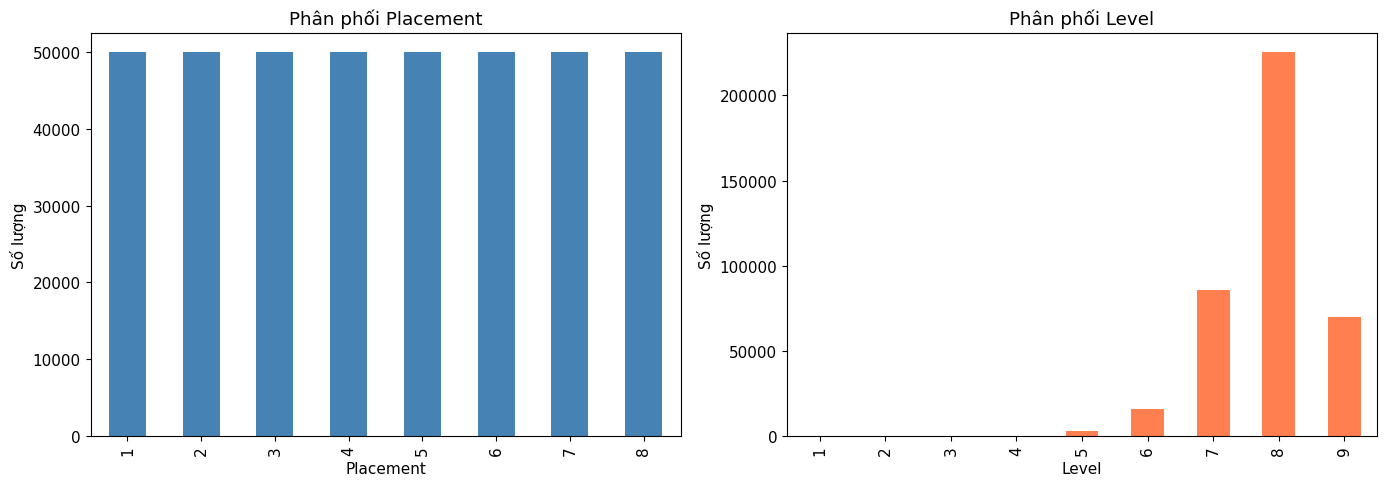

In [7]:
# Kiểm tra phân phối placement
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['placement'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Phân phối Placement')
axes[0].set_xlabel('Placement')
axes[0].set_ylabel('Số lượng')

df['level'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Phân phối Level')
axes[1].set_xlabel('Level')
axes[1].set_ylabel('Số lượng')

plt.tight_layout()
plt.show()

## 4. Gán nhãn Win/Lose

🏷️  Labels (Top 4): Win=199,871 (50%) | Lose=199,883 (50%)


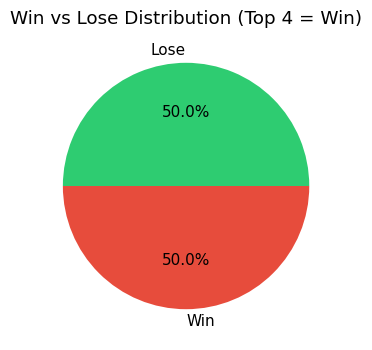

In [8]:
df = pp.label_win_lose(df, threshold=4)

# Visualize
fig, ax = plt.subplots(figsize=(6, 4))
df['result'].value_counts().plot(kind='pie', autopct='%1.1f%%', 
                                  colors=['#2ecc71', '#e74c3c'], ax=ax)
ax.set_title('Win vs Lose Distribution (Top 4 = Win)')
ax.set_ylabel('')
plt.show()

## 5. Tạo Transaction Format (cho ARM)

In [9]:
# Tạo transactions
transactions = pp.create_transactions(df, include_items=True, include_traits=True)

# Xem mẫu
print('\n📌 Mẫu transaction (Win):')
for t in list(transactions['win'])[:3]:
    print(f'  {set(t)}')

📦 Transactions: All=399,754 | Win=199,871 | Lose=199,883

📌 Mẫu transaction (Win):
  {'Item_69', 'Champ_JarvanIV', 'Trait_Set3_Celestial_3', 'Champ_XinZhao', 'Trait_StarGuardian_2', 'Champ_Neeko', 'Trait_Protector_4', 'Item_25', 'Trait_DarkStar_2', 'Item_46', 'Champ_Karma', 'Item_59', 'Trait_Set3_Mystic_4', 'Trait_Rebel_1', 'Champ_Sona', 'Champ_Soraka', 'Champ_Lulu', 'Champ_Rakan', 'Trait_TemplateTrait_1', 'Item_37', 'Item_27'}
  {'Trait_StarGuardian_1', 'Champ_AurelionSol', 'Item_99', 'Item_23', 'Champ_MissFortune', 'Trait_Mercenary_1', 'Trait_Starship_1', 'Champ_Malphite', 'Item_49', 'Trait_Blaster_2', 'Trait_Valkyrie_2', 'Trait_Set3_Blademaster_3', 'Item_12', 'Trait_Set3_Mystic_2', 'Item_7', 'Item_22', 'Champ_Jinx', 'Champ_MasterYi', 'Item_26', 'Champ_Sona', 'Champ_Yasuo', 'Champ_Kayle', 'Trait_Rebel_6', 'Champ_Soraka', 'Trait_Set3_Brawler_1', 'Item_37', 'Item_66'}
  {'Champ_Ekko', 'Champ_Fizz', 'Item_45', 'Trait_Infiltrator_4', 'Item_99', 'Champ_Annie', 'Item_23', 'Trait_Set3_Mysti

In [10]:
# Tạo binary matrix
print('\n=== Binary Matrix cho Win ===')
bin_win = pp.create_binary_matrix(transactions['win'])
print(bin_win.head())

print('\n=== Binary Matrix cho Lose ===')
bin_lose = pp.create_binary_matrix(transactions['lose'])
print(bin_lose.head())

print('\n=== Binary Matrix cho All ===')
bin_all = pp.create_binary_matrix(transactions['all'])
print(bin_all.head())


=== Binary Matrix cho Win ===


📐 Binary matrix shape: (199871, 452)
   Champ_Aatrox  Champ_Ahri  Champ_Amumu  Champ_Annie  Champ_Ashe  \
0         False       False        False        False       False   
1         False       False        False        False       False   
2         False       False        False         True       False   
3         False       False        False         True       False   
4         False       False        False        False       False   

   Champ_AurelionSol  Champ_Azir  Champ_Blitzcrank  Champ_Brand  Champ_Braum  \
0              False       False             False        False        False   
1               True       False             False        False        False   
2              False       False             False        False        False   
3              False       False             False        False        False   
4               True       False             False        False        False   

   ...  Trait_Wind_2  Trait_Wind_3  Trait_Wind_4  Trait_Wind_5  \
0

📐 Binary matrix shape: (199883, 428)
   Champ_Aatrox  Champ_Ahri  Champ_Amumu  Champ_Annie  Champ_Ashe  \
0         False       False        False        False       False   
1         False       False        False        False       False   
2         False       False        False        False       False   
3         False       False        False        False       False   
4         False       False        False         True       False   

   Champ_AurelionSol  Champ_Azir  Champ_Blitzcrank  Champ_Brand  Champ_Braum  \
0               True       False             False        False        False   
1              False       False             False        False        False   
2              False       False              True        False        False   
3              False       False              True        False        False   
4              False       False             False        False        False   

   ...  Trait_Warden_7  Trait_Wind_1  Trait_Wind_2  Trait_Wind_3  \

📐 Binary matrix shape: (399754, 455)
   Champ_Aatrox  Champ_Ahri  Champ_Amumu  Champ_Annie  Champ_Ashe  \
0         False       False        False        False       False   
1         False       False        False        False       False   
2         False       False        False         True       False   
3         False       False        False         True       False   
4         False       False        False        False       False   

   Champ_AurelionSol  Champ_Azir  Champ_Blitzcrank  Champ_Brand  Champ_Braum  \
0              False       False             False        False        False   
1               True       False             False        False        False   
2              False       False             False        False        False   
3              False       False             False        False        False   
4               True       False             False        False        False   

   ...  Trait_Wind_2  Trait_Wind_3  Trait_Wind_4  Trait_Wind_5  \
0

## 6. Tạo Co-occurrence Matrix (cho Graph Mining)

📊 Co-occurrence matrix (frequency): (107, 107)


📊 Co-occurrence matrix (winrate): (107, 107)


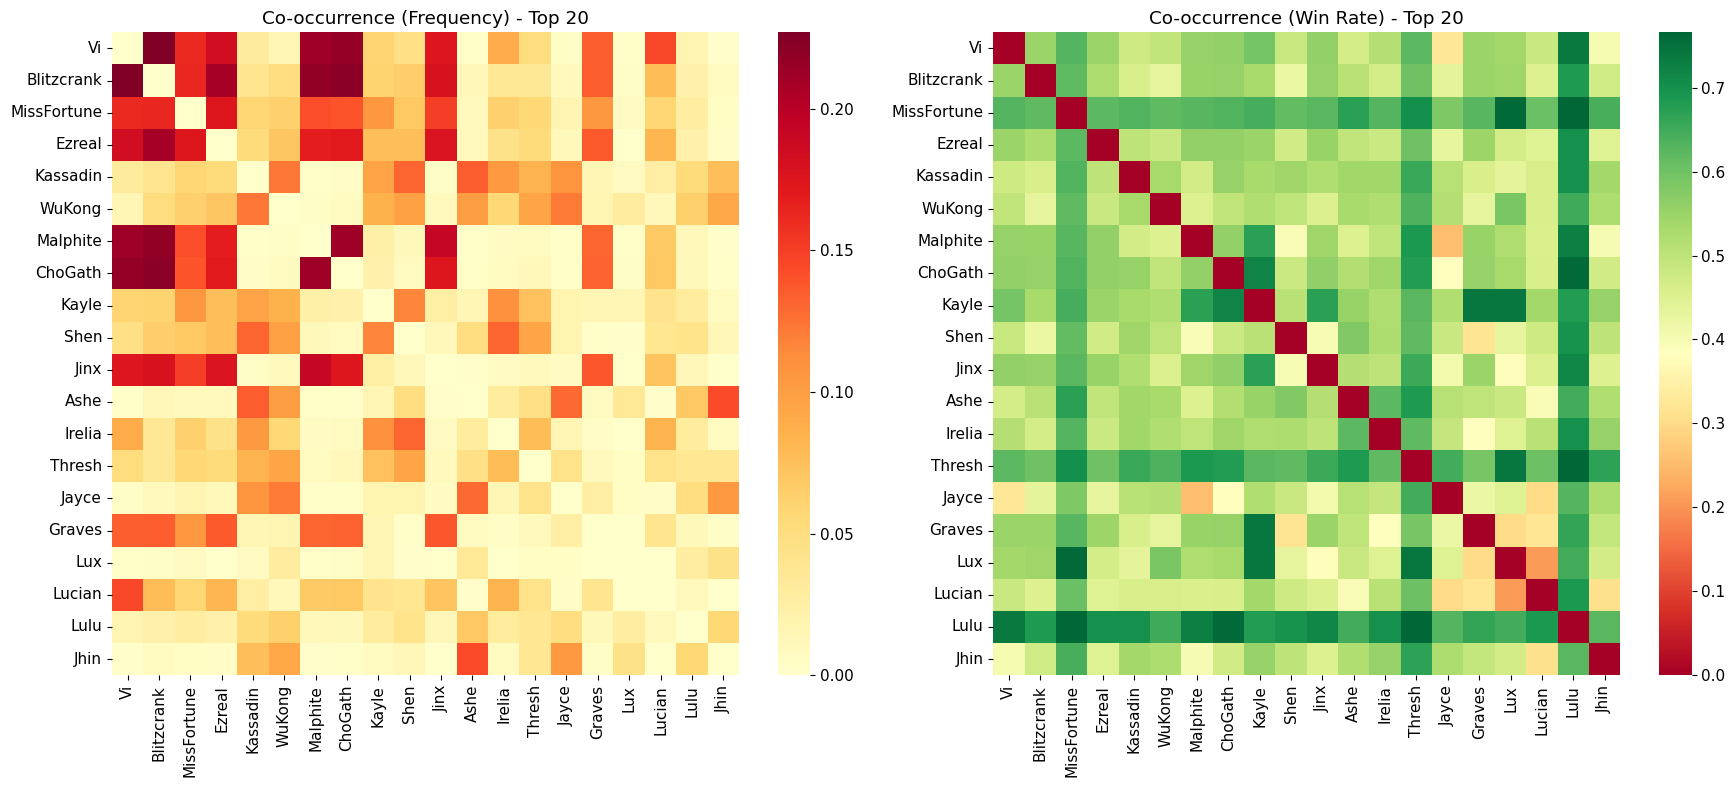

In [11]:
# Ma trận đồng xuất hiện theo tần suất
cooc_freq = pp.build_cooccurrence_matrix(df, entity='champions', weight='frequency')

# Ma trận đồng xuất hiện theo win-rate
cooc_wr = pp.build_cooccurrence_matrix(df, entity='champions', weight='winrate')

# Visualize top 20
top20 = cooc_freq.sum().nlargest(20).index
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

sns.heatmap(cooc_freq.loc[top20, top20], annot=False, cmap='YlOrRd', ax=axes[0])
axes[0].set_title('Co-occurrence (Frequency) - Top 20')

sns.heatmap(cooc_wr.loc[top20, top20], annot=False, cmap='RdYlGn', ax=axes[1])
axes[1].set_title('Co-occurrence (Win Rate) - Top 20')

plt.tight_layout()
plt.show()

## 7. Lưu dữ liệu đã xử lý

In [12]:
os.makedirs('../data/processed', exist_ok=True)

# Save processed dataframe
df.to_csv('../data/processed/tft_processed.csv', index=False)
print('✅ Saved: tft_processed.csv')

# Save binary matrices
bin_win.to_pickle('../data/processed/bin_win.pkl')
bin_lose.to_pickle('../data/processed/bin_lose.pkl')
bin_all.to_pickle('../data/processed/bin_all.pkl')
print('✅ Saved binary matrices')

# Save co-occurrence matrices
cooc_freq.to_pickle('../data/processed/cooc_frequency.pkl')
cooc_wr.to_pickle('../data/processed/cooc_winrate.pkl')
print('✅ Saved co-occurrence matrices')

# Summary
stats = pp.get_statistics(df)
print(f"\n📊 Tổng kết:")
print(f"   Records: {stats['total_records']:,}")
print(f"   Matches: {stats['total_matches']:,}")
print(f"   Champions: {stats['unique_champions']}")
print(f"   Items: {stats['unique_items']}")
print(f"   Win rate: {stats.get('win_rate', 0):.1%}")

✅ Saved: tft_processed.csv


✅ Saved binary matrices
✅ Saved co-occurrence matrices



📊 Tổng kết:
   Records: 399,754
   Matches: 49,977
   Champions: 107
   Items: 60
   Win rate: 50.0%
